# Más allá: calibrar antes de 2023, evaluar marzo de 2023 y leer la tensión inversa como un multiplicador

**Pregunta:** ¿Cuántas veces más rápido que las tablas LiST habrían tenido que salir los depósitos del banco para que sobreviviera solo 30 días, cuánto más lejos estuvo la corrida de marzo de 2023, y alcanza esa distancia una tasa calibrada solo con corridas anteriores?

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los notebooks 02, 04, 06 y 07 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook puedes:

- enunciar la afirmación BS-11 del producto (la tensión de liquidez inversa como un multiplicador de fuga, con una regla de rechazo, evaluada frente a una corrida rotulada) y decir qué deja abierto el estado del arte;
- calcular el multiplicador de las tres bases con el motor y ver que es un umbral, que el motor rechaza lo que no puede acotar y que un escalón en el período de supervivencia no rompe el viaje de ida y vuelta;
- ver la guarda de fuga de información en acción (calibrar antes de 2023, evaluar en 2023) y qué dice la evaluación;
- leer el multiplicador como una distancia: qué tan lejos estuvo la corrida de Silicon Valley Bank de la meta de 30 días.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
# Etiquetas en español de los semáforos de las pruebas de validación
LIGHTS = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cinco documentos versionados del caso C16, todos en `data/derived/C16/` (agregados reales del reporte de llamada de la FDIC del banco que quebró el 2023-03-10 hasta el 2022-12-31, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`):

- `reverse-stress.json`: el multiplicador de las tres bases con una meta de 30 días, con la curva, el viaje de ida y vuelta y el rechazo.
- `fast-run.json`: la variante de corrida rápida y su evaluación frente a las corridas de la Tabla A.1 (BCBS, 2023).
- `models-svb-liquidity.json`: la división de calibración y el generador de depositantes con su verdad conocida.
- `list-adverse.json` y `list-extreme.json`: las escaleras de las dos bases LiST.

Los montos están en miles de USD. La corrida observada es la de Silicon Valley Bank, 85% de los depósitos en 2 días (BCBS, 2023, Tabla A.1; Federal Reserve, 2023).

In [2]:
# Cargar los cinco documentos versionados (el notebook está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("reverse-stress", "fast-run", "models-svb-liquidity", "list-adverse", "list-extreme"):
    path = ROOT / "data" / "derived" / "C16" / f"{name}.json"
    documents[name] = json.loads(path.read_text(encoding="utf-8"))
    baked = documents[name]["provenance"]["riskvalidation_version"]
    print(name, "| calculado con riskvalidation", baked, "| instalado", rv.__version__)

reverse_doc = documents["reverse-stress"]
bases = {base["base_id"]: base for base in reverse_doc["outputs"]["bases"]}
conventions = reverse_doc["outputs"]["conventions"]
rows = {row["variant"]: row for row in conventions["variant_scenarios"]["rows"]}
target = reverse_doc["outputs"]["target"]["days"]
print("meta (días):", target, "| bases:", list(bases))

reverse-stress | calculado con riskvalidation 1.0.1 | instalado 1.0.1
fast-run | calculado con riskvalidation 1.0.1 | instalado 1.0.1
models-svb-liquidity | calculado con riskvalidation 1.0.1 | instalado 1.0.1
list-adverse | calculado con riskvalidation 1.0.1 | instalado 1.0.1
list-extreme | calculado con riskvalidation 1.0.1 | instalado 1.0.1
meta (días): 30 | bases: ['list-adverse', 'list-extreme', 'fast-run']


## Método

### Paso 1: el multiplicador de las tres bases

La tensión inversa pide el menor multiplicador $m^*$ de las tasas diarias de fuga (cada tasa limitada a 1 como máximo) con el que el período de supervivencia cae a la meta $T$ (notebook 06):

$$m^* = \min\{\, m \in [1, m_{\max}] : \mathrm{SP}(m) \le T \,\}, \qquad \mathrm{SP}(m^*) \le T < \mathrm{SP}(m^* - 10^{-6})$$

La celda siguiente reconstruye los tres escenarios base a partir de los segmentos versionados (la corrida rápida con la tasa calibrada en las filas anteriores a 2023, como en el notebook 04), construye el CBC efectivo del notebook 06. La celda siguiente resuelve con la meta del documento e imprime la razón cuando el motor rechaza.

In [3]:
# Reconstruir las tres bases desde los segmentos versionados y construir el CBC efectivo del notebook 06
from riskvalidation.liquidity.reverse import max_multiplier, solve_multiplier, survival_vs_multiplier
from riskvalidation.liquidity.runoff import LIST_PARAMETERS, TABLE_A1
from riskvalidation.liquidity.scenarios import Scenario, compose_scenario, fast_run_scenario, list_scenario

fit = fast_run_scenario([run for run in TABLE_A1 if run.year < 2023], "maximum-implied-daily-rate", scored=True)
built = {}
for base_id, severity in (("list-adverse", "adverse"), ("list-extreme", "extreme"), ("fast-run", "adverse")):
    lad = documents[base_id]["outputs"]["path"]["ladder"]
    row = rows[base_id]
    family, phase, horizon = row["scenario_family"], row["phase"], row["horizon_days"]
    segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
    if base_id == "fast-run":
        others = {k: v for k, v in segments.items() if k != "non-operational-corporate"}
        opening = segments["non-operational-corporate"][1]
        concentrated = {"non-operational-corporate": ("concentrated-uninsured", opening)}
        rest = compose_scenario(family, phase, list_scenario(severity), others, horizon)
        corporate = compose_scenario(family, phase, fit, concentrated, horizon)
        by_id = {s.segment_id: s for s in (*rest.segments, *corporate.segments)}
        scenario = Scenario(family, phase, horizon, tuple(by_id[k] for k in segments))
    else:
        scenario = compose_scenario(family, phase, list_scenario(severity), segments, horizon)
    contractual = np.array(lad["total_outflows"]) - scenario.outflows().sum(axis=0)
    effective_cbc = np.array(lad["cbc_total"]) + np.cumsum(lad["total_inflows"]) - np.cumsum(contractual)
    built[base_id] = (scenario, effective_cbc)
    print(base_id, "| horizonte (días):", scenario.horizon, "| segmentos:", len(scenario.segments))

list-adverse | horizonte (días): 125 | segmentos: 3
list-extreme | horizonte (días): 125 | segmentos: 3
fast-run | horizonte (días): 5 | segmentos: 3


La celda siguiente resuelve el multiplicador en la meta del documento para cada base e imprime la respuesta, o la razón cuando el motor rechaza.

In [4]:
# Resolver el multiplicador en la meta del documento e imprimir la respuesta o el rechazo
status_words = {"solved": "resuelto", "refused": "rechazado"}
for base_id, (scenario, effective_cbc) in built.items():
    answer = solve_multiplier(scenario, effective_cbc, target)
    cap = max_multiplier(scenario)
    print(f"{base_id:13s} | tope: {cap:9.4f} | {status_words[answer.status]} | m* = {answer.multiplier}")
    if answer.status == "refused":
        print("   ", bases[base_id]["solved"]["refusal_reason"]["es"])

list-adverse  | tope:  145.2346 | resuelto | m* = 2.118175
list-extreme  | tope:   93.8765 | resuelto | m* = 1.383141
fast-run      | tope:   18.4303 | rechazado | m* = None
    El objetivo de 30 días no es menor que el horizonte de 5 días, así que un periodo de supervivencia bajo él no se puede separar de sobrevivir el horizonte: no existe un intervalo.


### Paso 2: un escalón en el período de supervivencia

El período de supervivencia es un día entero, y un CBC que crece en los primeros días puede hacerlo saltar por encima de la meta: ningún multiplicador da entonces exactamente la meta. El motor devuelve el **umbral** (el menor $m$ con $\mathrm{SP}(m) \le T$), informa el período de supervivencia en él y justo por debajo, y la prueba de ida y vuelta acepta el escalón mientras la meta se alcance en $m^*$ y no justo por debajo. La base de corrida rápida tiene un horizonte de 5 días, así que la meta del documento (30 días) se rechaza; las metas bajo el horizonte se resuelven. La celda siguiente le pide a la base de corrida rápida metas de 5, 4, 3 y 1 días (una exploración, no filas versionadas) y corre la prueba de ida y vuelta sobre cada respuesta.

In [5]:
# Metas de 5, 4, 3 y 1 días sobre la base de corrida rápida, y la prueba de ida y vuelta de cada respuesta
from riskvalidation.validation.liquidity import reverse_stress_round_trip

scenario, effective_cbc = built["fast-run"]
print("horizonte de la base (días):", scenario.horizon, "| tope:", round(max_multiplier(scenario), 6))
for days in (5, 4, 3, 1):
    answer = solve_multiplier(scenario, effective_cbc, days)
    if answer.status == "refused":
        print(f"meta {days} | {status_words[answer.status]} | m* = {answer.multiplier}")
        continue
    below = answer.survival_just_below
    test = reverse_stress_round_trip(
        answer.multiplier, answer.survival_at_multiplier, days, 0.0, survival_just_below=below
    )
    print(f"meta {days} | {status_words[answer.status]} | m* = {answer.multiplier}")
    print(f"         supervivencia en m*: {answer.survival_at_multiplier}")
    print(f"         justo bajo m*: {below.day} | ida y vuelta: {test.statistic} {LIGHTS[test.light.value]}")

horizonte de la base (días): 5 | tope: 18.430329
meta 5 | rechazado | m* = None
meta 4 | resuelto | m* = 2.06764
         supervivencia en m*: 4
         justo bajo m*: 5 | ida y vuelta: 0.0 verde
meta 3 | resuelto | m* = 2.669936
         supervivencia en m*: 1
         justo bajo m*: 4 | ida y vuelta: 0.0 verde
meta 1 | resuelto | m* = 2.669936
         supervivencia en m*: 1
         justo bajo m*: 4 | ida y vuelta: 0.0 verde


La celda siguiente dibuja el período de supervivencia frente al multiplicador para las tres bases, con la meta de 30 días como línea horizontal. Una base que sobrevive su horizonte se dibuja en el horizonte.

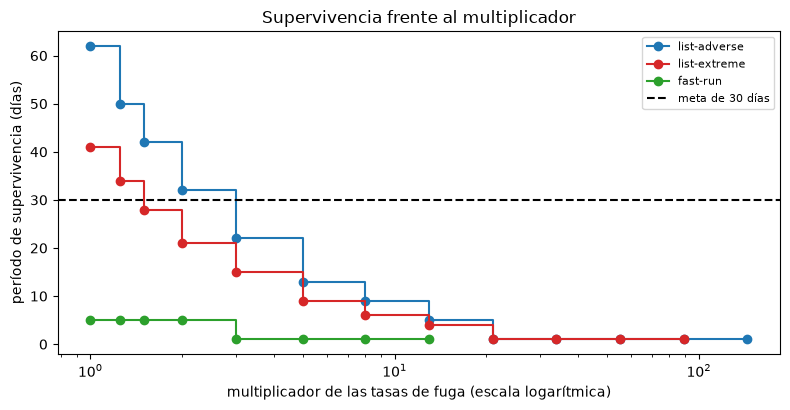

In [6]:
# Dibujar el período de supervivencia frente al multiplicador para las tres bases, con la meta de 30 días
grid_all = conventions["runoff_multiplier_grid"]["values"]
fig, ax = plt.subplots(figsize=(8, 4.2))
for (base_id, (scenario, effective_cbc)), color in zip(built.items(), ("tab:blue", "tab:red", "tab:green")):
    grid = np.array([m for m in grid_all if m <= max_multiplier(scenario)])
    results = survival_vs_multiplier(scenario, effective_cbc, grid)
    days = [scenario.horizon if r.survives else r.day for r in results]
    ax.step(grid, days, where="post", marker="o", color=color, label=base_id)
ax.axhline(target, color="black", linestyle="--", label="meta de 30 días")
ax.set_xscale("log")
ax.set_xlabel("multiplicador de las tasas de fuga (escala logarítmica)")
ax.set_ylabel("período de supervivencia (días)")
ax.set_title("Supervivencia frente al multiplicador")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Las bases LiST cruzan la línea de 30 días en los multiplicadores resueltos arriba, 2,118175 y 1,383141, y siguen cayendo hasta 1 día; la corrida rápida, dibujada en su horizonte de 5 días mientras sobrevive, nunca llega a 30 y baja de 5 con un multiplicador de cerca de 2,07 (4 días con 2,06764) y a 1 día con 2,669936, donde el período de supervivencia salta de 4 días a 1. Ese escalón es el caso del notebook: ningún multiplicador da exactamente 3 días, el motor devuelve el umbral e informa ambos períodos de supervivencia, y el viaje de ida y vuelta se queda en 0,0. La figura muestra tres curvas de una misma familia; no dice cuál de las tres bases es plausible.

### Paso 3: calibrar antes de 2023, evaluar en marzo de 2023

La tasa de la corrida rápida es un estadístico de las tasas diarias implícitas de la Tabla A.1, $q_i = 1-(1-F_i)^{1/n_i}$, y la regla del documento es el máximo. El protocolo está libre de fuga de información por construcción: la calibración usa las cuatro filas anteriores a 2023, el motor rechaza una fila de 2023 en una llamada evaluada, y las filas de 2023 son contra lo que se evalúa la variante; la observación de Silicon Valley Bank es un ancla rotulada (`forecast_claim` es falso), nunca un pronóstico. La celda siguiente muestra la calibración, el rechazo y el ancla, y la que sigue evalúa la variante sobre las filas que su escalera de 5 días alcanza.

In [7]:
# La calibración con las filas anteriores a 2023, el rechazo de una fila de 2023 y el ancla
from riskvalidation.liquidity.scenarios import anchor_from_observation

calibration = documents["models-svb-liquidity"]["fit"]["calibration"]
print("calibrada con:", calibration["split"]["calibrated_on"])
print("evaluada con:", calibration["split"]["scored_on"])
print("tasa ajustada (máxima tasa diaria implícita):", round(fit.daily_rate, 8))
try:
    fast_run_scenario(list(TABLE_A1), "maximum-implied-daily-rate", scored=True)
except ValueError:
    print("una llamada evaluada con una fila de 2023 es rechazada por el motor (ValueError)")

anchor = anchor_from_observation(0.85, 2)
print("ancla del motor, tasa diaria implícita:", round(anchor["implied_daily_rate"], 6))
print("el ancla es un pronóstico:", "sí" if anchor["forecast_claim"] else "no")

calibrada con: ['icesave-2008', 'northern-rock-2007', 'wamu-2008', 'indymac-2008']
evaluada con: ['svb-2023', 'first-republic-2023', 'svb-uk-2023', 'credit-suisse-2023', 'signature-2023']
tasa ajustada (máxima tasa diaria implícita): 0.05425839
una llamada evaluada con una fila de 2023 es rechazada por el motor (ValueError)
ancla del motor, tasa diaria implícita: 0.612702
el ancla es un pronóstico: no


La celda siguiente evalúa la corrida rápida sobre las corridas que alcanza su escalera de 5 días: la proporción modelada es la salida acumulada de su escenario reconstruido sobre la base de depósitos del modelo, y la contrastación del producto la pone frente a la proporción observada. Una fila anterior a 2023 es una fila con la que se calibró la tasa; una fila de 2023 se evalúa fuera de muestra.

In [8]:
# Evaluar la corrida rápida sobre las corridas que alcanza su escalera de 5 días, con la contrastación del producto
from riskvalidation.validation.liquidity import runoff_adequacy_back_test

scenario, _ = built["fast-run"]
base_deposits = documents["fast-run"]["outputs"]["scoring"]["model_deposit_base"]
outflow_by_day = np.cumsum(scenario.outflows().sum(axis=0))
scored = []
print(f"{'fila':22s}{'rol':>13s}{'observada':>11s}{'modelada':>10s}{'error':>9s}{'razón':>8s}")
for run in TABLE_A1:
    if run.days > scenario.horizon:
        continue
    modelled = outflow_by_day[run.days - 1] / base_deposits
    test = runoff_adequacy_back_test(modelled, run.outflow_share, compared_at="event-horizon", denominator=run.row_id)
    role = "calibración" if run.year < 2023 else "evaluada"
    scored.append((run.row_id, role, run.outflow_share, modelled))
    left = f"{run.row_id:22s}{role:>13s}{run.outflow_share:11.2f}{modelled:10.4f}"
    print(left + f"{test.metric:9.4f}{test.statistic:8.3f}")

fila                            rol  observada  modelada    error   razón
svb-2023                   evaluada       0.85    0.1708   0.6792   0.201
svb-uk-2023                evaluada       0.30    0.1263   0.1737   0.421
signature-2023             evaluada       0.20    0.1263   0.0737   0.631
northern-rock-2007      calibración       0.20    0.2528  -0.0528   1.264


La celda siguiente dibuja la proporción observada y la modelada de cada corrida que alcanza la corrida rápida.

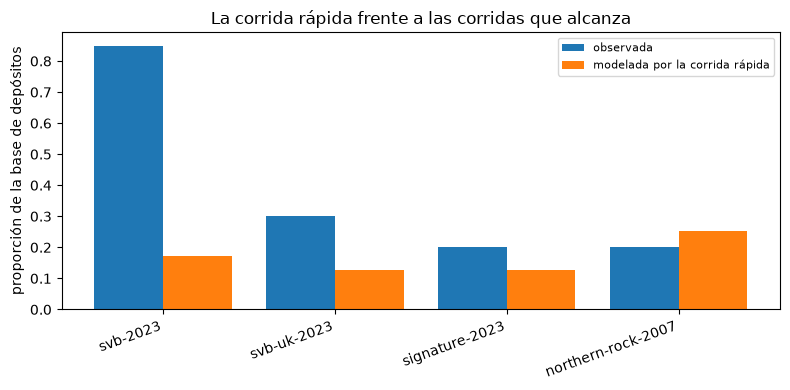

In [9]:
# Dibujar la proporción observada y la modelada de cada corrida que alcanza la corrida rápida
labels = [row_id for row_id, _, _, _ in scored]
position = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(position - 0.2, [item[2] for item in scored], width=0.4, label="observada")
ax.bar(position + 0.2, [item[3] for item in scored], width=0.4, label="modelada por la corrida rápida")
ax.set_xticks(position)
ax.set_xticklabels(labels, rotation=20, ha="right")
ax.set_ylabel("proporción de la base de depósitos")
ax.set_title("La corrida rápida frente a las corridas que alcanza")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

La tasa calibrada con las cuatro corridas anteriores a 2023, 0,05425839 al día, reproduce la corrida con la que se ajustó (Northern Rock: 0,2528 modelado frente a 0,20 observado, cubierta de más en 0,0528) y queda muy corta frente a las tres corridas de 2023 que alcanza su escalera: 0,1708 frente al 0,85 de SVB, 0,1263 frente a 0,30 de SVB UK y 0,1263 frente a 0,20 de Signature. La guarda funciona como se diseñó y el resultado no es halagador: las corridas de 2023 fueron más rápidas que cualquier corrida anterior de la Tabla A.1, así que una tasa construida solo con historia previa no las alcanza. La figura no dice que una tasa más rápida sería la correcta; el ancla sigue siendo una observación y nunca un pronóstico.

## Estado del arte

- **Escenarios hacia adelante.** La prueba de tensión de liquidez de 2019 del BCE fija primero los escenarios (tasas diarias suaves compuestas por severidad) e informa el período de supervivencia que dan (BCE, 2019, nota metodológica y anexo de resultados).
- **Variedad de escenarios.** El Principio 10 de los principios de Basilea pide pruebas de tensión en muchos escenarios, individualmente y en combinación (BCBS, 2008); no dice cómo encontrar el escenario que quiebra a un banco dado.
- **La evidencia de 2023.** El informe sobre la turbulencia de 2023 dice que los supuestos de velocidad fueron reajustados por corridas como el 85% de los depósitos en 2 días y lista como preguntas abiertas métricas como una capacidad de contrapeso a cinco días y el período de supervivencia (BCBS, 2023); la Reserva Federal encontró que la prueba de tensión interna de liquidez del banco se apoyaba en referencias de pares no comparables (Federal Reserve, 2023).
- **La tensión inversa en la investigación.** El dosier de investigación lista la tensión de liquidez inversa como el último peldaño de su escalera de modelos de liquidez ("el multiplicador de fuga con el que el período de supervivencia cae bajo una meta, por ejemplo 30 días") sin un caso medido, y no encontró ninguna herramienta que la implemente (UNVERIFIED más allá de la búsqueda del dosier).

## Más allá del estado del arte

**BS-11**, tal como lo enuncia el SDD: el producto responde la pregunta inversa con un número que tiene tres propiedades que el estado del arte deja abiertas.

1. **Un umbral, no una estimación.** El multiplicador de las tasas diarias de fuga con el que el período de supervivencia cae por primera vez a la meta, limitado para que ninguna tasa pase de 1, con el período de supervivencia en él y justo por debajo (pasos 1 y 2);
2. **Una regla de rechazo.** Una meta que no puede acotarse (no menor que el horizonte, ya alcanzada en la base, inalcanzable bajo el tope) se rechaza con su razón y no se devuelve ningún número (paso 1, la corrida rápida; paso 2);
3. **Una corrida resguardada y rotulada.** La base de corrida rápida se calibra solo con las filas anteriores a 2023, el motor rechaza una fila de 2023 en una llamada evaluada, y las filas de 2023 la evalúan, con la observación de Silicon Valley Bank como ancla y nunca como pronóstico (paso 3).

La evidencia es el cálculo de arriba, que corre el motor sobre los documentos versionados. Lo que agrega es una forma de leer la distancia entre una prueba de tensión y una corrida real: el multiplicador. La celda siguiente calcula esa distancia. Para cada base LiST, $m_{\mathrm{SVB}}$ es el multiplicador que lleva la tasa de la clase corporativa no asegurada a la tasa diaria implícita de Silicon Valley Bank, $m_{\mathrm{SVB}} = q_{\mathrm{SVB}} / q_{\text{clase}}$; el motor da el período de supervivencia bajo él, y la razón $m_{\mathrm{SVB}} / m^*$ dice cuántas veces más lejos está la corrida de 2023 que la meta de 30 días.

In [10]:
# El multiplicador que lleva la tasa LiST de la clase corporativa no asegurada a la tasa de SVB, frente al umbral
svb = next(run for run in TABLE_A1 if run.row_id == "svb-2023")
corporate = "non-operational-non-financial-corporates"
distance = {}
print("tasa diaria implícita de SVB:", round(svb.implied_daily_rate, 6))
for base_id, severity in (("list-adverse", "adverse"), ("list-extreme", "extreme")):
    scenario, effective_cbc = built[base_id]
    m_star = solve_multiplier(scenario, effective_cbc, target).multiplier
    m_svb = svb.implied_daily_rate / LIST_PARAMETERS[severity]["open_maturity"][corporate]
    at_svb = survival_vs_multiplier(scenario, effective_cbc, np.array([1.0, m_svb]))[1]
    distance[base_id] = (m_star, m_svb)
    print(f"{base_id:13s} | m* = {m_star} | m_SVB = {m_svb:.4f} | tope: {max_multiplier(scenario):.4f}")
    print(f"   período de supervivencia en m_SVB (día): {at_svb.day} | m_SVB / m* = {m_svb / m_star:.2f}")

tasa diaria implícita de SVB: 0.612702
list-adverse  | m* = 2.118175 | m_SVB = 88.9855 | tope: 145.2346
   período de supervivencia en m_SVB (día): 1 | m_SVB / m* = 42.01
list-extreme  | m* = 1.383141 | m_SVB = 57.5183 | tope: 93.8765
   período de supervivencia en m_SVB (día): 1 | m_SVB / m* = 41.59


La celda siguiente dibuja el multiplicador umbral de cada base LiST frente al multiplicador de la corrida de 2023, en un eje logarítmico.

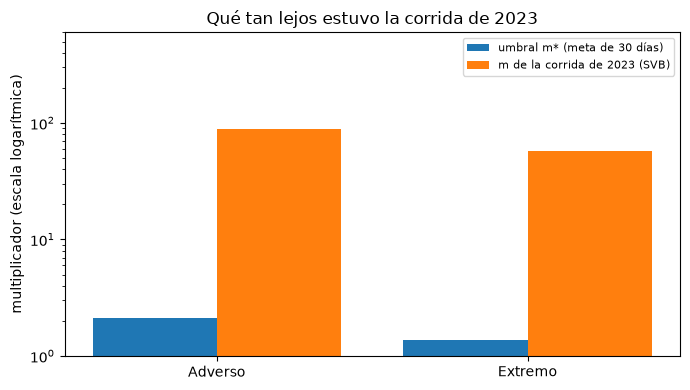

In [11]:
# Dibujar el multiplicador umbral de cada base LiST frente al multiplicador de la corrida de 2023
positions = np.arange(2)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(positions - 0.2, [distance[b][0] for b in distance], width=0.4, label="umbral m* (meta de 30 días)")
ax.bar(positions + 0.2, [distance[b][1] for b in distance], width=0.4, label="m de la corrida de 2023 (SVB)")
ax.set_yscale("log")
ax.set_ylim(1, 600)
ax.set_xticks(positions)
ax.set_xticklabels(["Adverso", "Extremo"])
ax.set_ylabel("multiplicador (escala logarítmica)")
ax.set_title("Qué tan lejos estuvo la corrida de 2023")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Dos barras por base, y la segunda es unas cuarenta veces la primera. El umbral de 30 días es un múltiplo pequeño de las tablas, 2,118175 bajo Adverso y 1,383141 bajo Extremo, y el multiplicador que reproduciría la tasa de SVB es 88,9855 y 57,5183; con esos multiplicadores el período de supervivencia es 1 día en ambas bases. Las razones, 42,01 y 41,59, son la afirmación de este notebook en un número: una prueba de tensión que se supera con un multiplicador de 2 dice poco de un banco que puede enfrentar un multiplicador de 89. El multiplicador escala todos los segmentos a la vez, así que la figura no dice qué segmento o qué día se rompe primero.

## Resultados

**Respuesta:** Para sobrevivir solo 30 días los depósitos del banco habrían tenido que salir 2,118175 veces más rápido que la tabla LiST Adverso, o 1,383141 veces más rápido que la Extrema. La corrida de marzo de 2023 estuvo muy más allá: el multiplicador que lleva la tasa Adversa de la clase corporativa no asegurada a la tasa de SVB es 88,9855 (57,5183 en la base Extrema), 42,01 y 41,59 veces los umbrales, y con esos multiplicadores el período de supervivencia es 1 día. Una tasa calibrada solo con corridas anteriores a 2023, 0,05425839 al día, no cierra la brecha: evaluada en SVB modela 0,1708 frente al 0,85 observado.

- **El umbral.** El motor devuelve los multiplicadores con la meta de 30 días: 2,118175 en la base LiST Adverso y 1,383141 en la base Extremo. Los topes (145,2346 y 93,8765) son más de sesenta veces mayores, así que las respuestas quedan lejos del tope.
- **El rechazo y el escalón.** La base de corrida rápida se rechaza con la meta de 30 días y con 5 días, porque ninguna es menor que su horizonte de 5 días, y no devuelve ningún número. Para 4 días el umbral es 2,06764 (4 días en él, 5 justo por debajo); para 3 y 1 días es 2,669936, donde el período de supervivencia salta de 4 días a 1: ningún multiplicador da exactamente 3 días, el motor devuelve el umbral e informa ambos períodos de supervivencia, y el viaje de ida y vuelta sigue verde (0,0).
- **La calibración resguardada.** La tasa calibrada con las cuatro filas anteriores a 2023 es 0,05425839, y el motor rechaza una fila de 2023 en una llamada evaluada. Evaluada en marzo de 2023, la corrida rápida modela 0,1708 frente al 0,85 de SVB (un error de 0,6792), 0,1263 frente al 0,30 de SVB UK (0,1737) y 0,1263 frente al 0,20 de Signature (0,0737); en una fila con la que se calibró, Northern Rock, cubre de más en 0,0528. La guarda funciona y el resultado no es halagador: la corrida de 2023 fue más rápida que cualquiera anterior en la Tabla A.1.
- **La distancia a la corrida de 2023.** El multiplicador que lleva la tasa LiST de la clase corporativa no asegurada a la tasa de SVB es 88,9855 en la base Adversa y 57,5183 en la Extrema, y con esos multiplicadores el período de supervivencia es de 1 día en ambas. Frente a los umbrales de 2,118175 y 1,383141 las razones son 42,01 y 41,59: la corrida de 2023 estuvo unas cuarenta veces más lejos de las tasas LiST que la meta de 30 días. Una prueba de tensión que se supera con un multiplicador de 2 dice poco de un banco que puede enfrentar un multiplicador de 89.

Dónde se detiene la afirmación. El banco es real en agregado y sintético en comportamiento y depósitos: los multiplicadores muestran el método con esos parámetros, no la holgura del banco. La meta, la grilla de multiplicadores, el calendario de monetización y la regla de calibración son convenciones declaradas del producto (los dosieres no fijan ninguna). El multiplicador escala las tasas de todos los segmentos a la vez; no dice qué segmento, ni qué día, se rompe primero. Y la ausencia de una herramienta previa es UNVERIFIED más allá de la búsqueda del dosier.

## Resumen

- BS-11 se demuestra sobre los documentos versionados: los multiplicadores 2,118175 (Adverso) y 1,383141 (Extremo) son umbrales que el motor resuelve, con el período de supervivencia en ellos y justo debajo.
- Una meta que no puede acotarse se rechaza con su razón, y un escalón del período de supervivencia más allá de la meta se informa, no se esconde.
- La corrida rápida se calibra antes de 2023 y se evalúa en 2023 por una regla del código; evaluada en SVB queda corta, y el ancla nunca es un pronóstico.
- El multiplicador lee la distancia entre una prueba de tensión y una corrida real: la meta de 30 días es un múltiplo pequeño de las tasas de LiST, y la corrida de 2023 está unas cuarenta veces más lejos.

**Qué probar a continuación.** Resuelve la base Adversa para una meta de 14 días y compara su multiplicador con el de la corrida de 2023; luego lee la sección del SDD sobre las afirmaciones del producto.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10. https://www.bis.org/publ/bcbs144.htm
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf